# Comprobaciones reproducibles

Este cuaderno acompaña las demostraciones con cálculos simbólicos, diferencias
finitas y ejemplos numéricos. Los valores elegidos son **ejemplos didácticos
auxiliares**; no sustituyen las hipótesis ni las demostraciones analíticas.

**Sobre el ejercicio MLP.** El documento no incluye la red ni los pesos iniciales
a los que se refiere ese ejercicio. Por ello aquí no se presenta una solución
numérica inventada. Véase el [capítulo de entrenamiento de MLP](../capitulos/01_entrenamiento_mlp.md).

Se puede ejecutar de principio a fin con Python, NumPy, SymPy y Matplotlib.
Las figuras se guardan en la carpeta figuras del proyecto.


In [1]:
from pathlib import Path
import sys

import numpy as np
import sympy as sp
import matplotlib

# El script guarda gráficos sin necesitar una ventana. En Jupyter se conserva
# el backend configurado por el cuaderno.
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

if "__file__" in globals():
    RAIZ = Path(__file__).resolve().parents[1]
else:
    RAIZ = Path.cwd()
    if RAIZ.name == "notebooks":
        RAIZ = RAIZ.parent
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
})
COLORES = ["#1764a0", "#cb4b16", "#238b64"]
np.set_printoptions(precision=8, suppress=True)


def guardar_figura(figura, nombre):
    """Guardar la misma figura como PNG y SVG."""
    figura.savefig(FIGURAS / f"{nombre}.png", dpi=170, bbox_inches="tight")
    figura.savefig(FIGURAS / f"{nombre}.svg", bbox_inches="tight")
    print(f"Figura guardada: figuras/{nombre}.png")


def diferencias_centrales(funcion, valores, epsilon=1e-6):
    """Aproximar todas las derivadas parciales de una función escalar."""
    valores = np.asarray(valores, dtype=float)
    gradiente = np.empty_like(valores)
    for indice in np.ndindex(valores.shape):
        mas = valores.copy()
        menos = valores.copy()
        mas[indice] += epsilon
        menos[indice] -= epsilon
        gradiente[indice] = (
            funcion(mas) - funcion(menos)
        ) / (2.0 * epsilon)
    return gradiente


print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("SymPy:", sp.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Todos los ejemplos usan valores fijados explícitamente.")


Python: 3.12.14
NumPy: 2.3.5
SymPy: 1.14.0
Matplotlib: 3.10.8
Todos los ejemplos usan valores fijados explícitamente.


## 1. Derivada de la sigmoide

Para $f(z)=(1+e^{-az})^{-1}$ verificamos simbólicamente
$f'(z)-af(z)(1-f(z))=0$. La gráfica muestra tres valores positivos de $a$
y las correspondientes derivadas. La comprobación simbólica trata $a$
como una constante real.


f'(z) - a f(z) (1 - f(z)) = 0
f(0), con a=1 = 1/2
f'(0), con a=1 = 1/4
Figura guardada: figuras/sigmoide.png


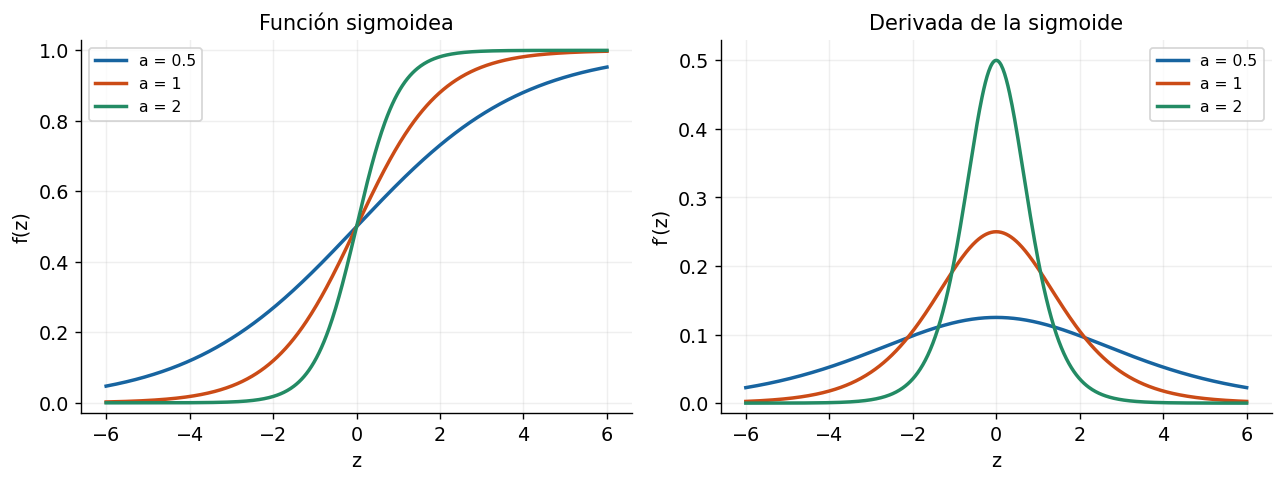

In [2]:
z, a = sp.symbols("z a", real=True)
f = 1 / (1 + sp.exp(-a * z))
residuo_sigmoide = sp.simplify(sp.diff(f, z) - a * f * (1 - f))
assert residuo_sigmoide == 0
print("f'(z) - a f(z) (1 - f(z)) =", residuo_sigmoide)
print("f(0), con a=1 =", f.subs({z: 0, a: 1}))
print("f'(0), con a=1 =", sp.diff(f, z).subs({z: 0, a: 1}))

z_grafica = np.linspace(-6, 6, 601)
fig, ejes = plt.subplots(1, 2, figsize=(10.4, 4.0))
for a_valor, color in zip((0.5, 1.0, 2.0), COLORES):
    f_valores = 1 / (1 + np.exp(-a_valor * z_grafica))
    df_valores = a_valor * f_valores * (1 - f_valores)
    ejes[0].plot(z_grafica, f_valores, color=color,
                 label=f"a = {a_valor:g}", linewidth=2)
    ejes[1].plot(z_grafica, df_valores, color=color,
                 label=f"a = {a_valor:g}", linewidth=2)
for eje in ejes:
    eje.set_xlabel("z")
    eje.grid(alpha=0.2)
    eje.legend()
ejes[0].set(title="Función sigmoidea", ylabel="f(z)", ylim=(-0.03, 1.03))
ejes[1].set(title="Derivada de la sigmoide", ylabel="f′(z)", ylim=(-0.015, 0.53))
fig.tight_layout()
guardar_figura(fig, "sigmoide")
plt.show()
plt.close(fig)


## 2. Tamaño de paso con el gradiente completo

Tomamos $J(\theta)=\theta^2$, equivalente a $x=1$, $y=0$ y
$\Sigma_x=1$, con $\theta^{(0)}=1$.
Como $\nabla J(\theta)=2\theta$,
$\theta^{(t+1)}=(1-2\mu)\theta^{(t)}$.

La condición de convergencia es $0<\mu<1$. Comparamos $\mu=0.25$,
$\mu=0.75$ y $\mu=1.1$. Los dos primeros pasos generan pérdidas iguales:
sus factores son $0.5$ y $-0.5$, aunque los parámetros tienen signos
diferentes. El tercer caso tiene factor $-1.2$ y diverge.


mu=0.25 | factor= 0.50 | J(theta_12)=5.96046448e-08 | converge
mu=0.75 | factor=-0.50 | J(theta_12)=5.96046448e-08 | converge
mu=1.10 | factor=-1.20 | J(theta_12)=79.4968472 | diverge

t       theta(mu=0.25)    theta(mu=0.75)    theta(mu=1.1)
0            1.000000         1.000000         1.000000
1            0.500000        -0.500000        -1.200000
2            0.250000         0.250000         1.440000
3            0.125000        -0.125000        -1.728000
4            0.062500         0.062500         2.073600
5            0.031250        -0.031250        -2.488320
6            0.015625         0.015625         2.985984
Figura guardada: figuras/paso_gradiente.png


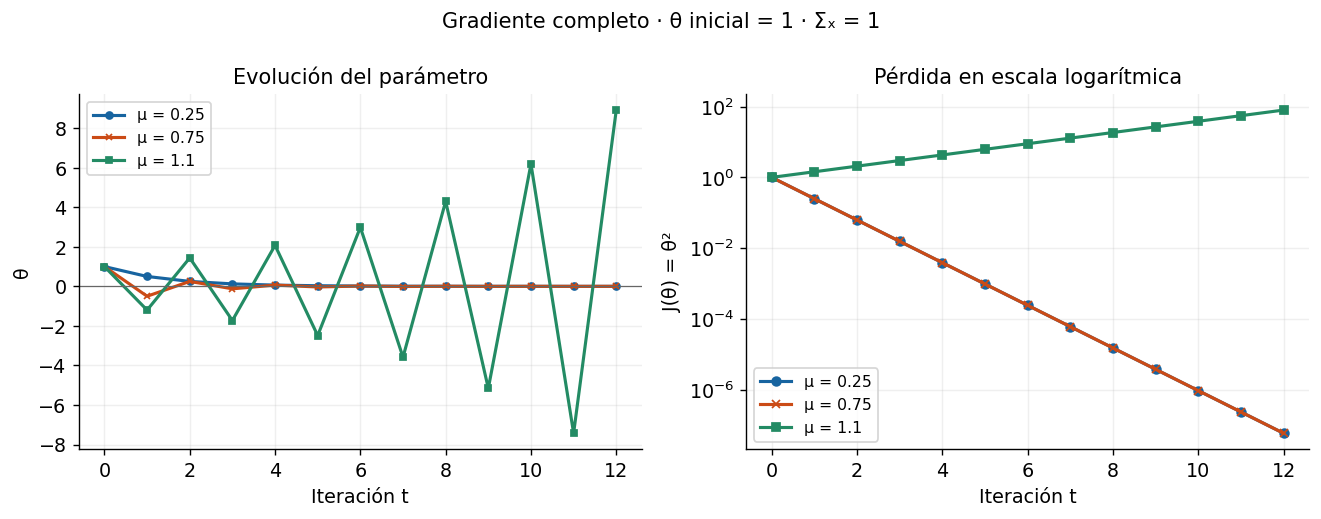

In [3]:
pasos = (0.25, 0.75, 1.1)
tiempos = np.arange(13)
trayectorias = {}
for mu in pasos:
    theta = np.empty(len(tiempos))
    theta[0] = 1.0
    for t in range(len(tiempos) - 1):
        theta[t + 1] = theta[t] - mu * 2.0 * theta[t]
    np.testing.assert_allclose(theta, (1.0 - 2.0 * mu) ** tiempos)
    trayectorias[mu] = theta
    tendencia = "converge" if abs(1 - 2 * mu) < 1 else "diverge"
    print(
        f"mu={mu:4.2f} | factor={1-2*mu:5.2f} | "
        f"J(theta_12)={theta[-1]**2:.9g} | {tendencia}"
    )

assert np.all(np.diff(trayectorias[0.25] ** 2) < 0)
assert np.all(np.diff(trayectorias[0.75] ** 2) < 0)
assert np.all(np.diff(trayectorias[1.1] ** 2) > 0)
print("\nt       theta(mu=0.25)    theta(mu=0.75)    theta(mu=1.1)")
for t in range(7):
    print(
        f"{t:1d}       {trayectorias[0.25][t]:13.6f}"
        f"    {trayectorias[0.75][t]:13.6f}"
        f"    {trayectorias[1.1][t]:13.6f}"
    )

fig, ejes = plt.subplots(1, 2, figsize=(10.7, 4.2))
for mu, color, marcador in zip(pasos, COLORES, ("o", "x", "s")):
    theta = trayectorias[mu]
    ejes[0].plot(
        tiempos, theta, color=color, marker=marcador, markersize=4,
        linewidth=1.8, label=f"μ = {mu:g}"
    )
    ejes[1].semilogy(
        tiempos, theta**2, color=color, marker=marcador,
        markersize=5, linewidth=1.8, label=f"μ = {mu:g}"
    )
ejes[0].axhline(0, color="#666666", linewidth=0.7)
ejes[0].set(title="Evolución del parámetro", ylabel="θ")
ejes[1].set(title="Pérdida en escala logarítmica", ylabel="J(θ) = θ²")
for eje in ejes:
    eje.set_xlabel("Iteración t")
    eje.set_xticks(np.arange(0, 13, 2))
    eje.grid(alpha=0.2)
    eje.legend()
fig.suptitle("Gradiente completo · θ inicial = 1 · Σₓ = 1", fontsize=12)
fig.tight_layout()
guardar_figura(fig, "paso_gradiente")
plt.show()
plt.close(fig)


## 3. Gradientes de una capa convolucional

Usamos el ejemplo del capítulo: entrada $3\times3$, filtro $2\times2$,
stride $1$, sin padding y sesgo $b=1$. La función escalar auxiliar es
$\mathcal L=\sum_{i,j}O(i,j)$, por lo que $\delta(i,j)=1$.

Las diferencias centrales evalúan la función de salida al perturbar
**cada uno de los 14 valores**: 9 de la entrada, 4 del filtro y el sesgo.
Su comparación con el gradiente analítico comprueba también los índices
y las contribuciones acumuladas en las posiciones compartidas.


In [4]:
I = np.arange(1, 10, dtype=float).reshape(3, 3)
h = np.array([[1.0, 0.0], [0.0, -1.0]])
b = 1.0


def salida_convolucional(entrada, filtro, sesgo):
    alto, ancho = entrada.shape
    alto_filtro, ancho_filtro = filtro.shape
    salida = np.empty((alto - alto_filtro + 1, ancho - ancho_filtro + 1))
    for i in range(salida.shape[0]):
        for j in range(salida.shape[1]):
            parche = entrada[i:i + alto_filtro, j:j + ancho_filtro]
            salida[i, j] = np.sum(parche * filtro) + sesgo
    return salida


O = salida_convolucional(I, h, b)
delta = np.ones_like(O)
grad_h = np.zeros_like(h)
grad_I = np.zeros_like(I)
for i in range(O.shape[0]):
    for j in range(O.shape[1]):
        grad_h += delta[i, j] * I[i:i + h.shape[0], j:j + h.shape[1]]
        grad_I[i:i + h.shape[0], j:j + h.shape[1]] += delta[i, j] * h
grad_b = delta.sum()

grad_h_fd = diferencias_centrales(
    lambda filtro: salida_convolucional(I, filtro, b).sum(), h
)
grad_I_fd = diferencias_centrales(
    lambda entrada: salida_convolucional(entrada, h, b).sum(), I
)
epsilon = 1e-6
grad_b_fd = (
    salida_convolucional(I, h, b + epsilon).sum()
    - salida_convolucional(I, h, b - epsilon).sum()
) / (2 * epsilon)

np.testing.assert_allclose(grad_h, [[12, 16], [24, 28]])
np.testing.assert_allclose(
    grad_I, [[1, 1, 0], [1, 0, -1], [0, -1, -1]]
)
for analitico, numerico in (
    (grad_h, grad_h_fd), (grad_I, grad_I_fd), (grad_b, grad_b_fd)
):
    np.testing.assert_allclose(analitico, numerico, atol=1e-7, rtol=1e-7)

print("Salida O:\n", O)
print("Gradiente respecto al filtro:\n", grad_h)
print("Gradiente respecto a la entrada:\n", grad_I)
print("Gradiente respecto al sesgo:", grad_b)
print("Error máximo, filtro:", np.max(np.abs(grad_h - grad_h_fd)))
print("Error máximo, entrada:", np.max(np.abs(grad_I - grad_I_fd)))
print("Error absoluto, sesgo:", abs(grad_b - grad_b_fd))
print("Comprobación satisfactoria de 14 derivadas parciales.")


Salida O:
 [[-3. -3.]
 [-3. -3.]]
Gradiente respecto al filtro:
 [[12. 16.]
 [24. 28.]]
Gradiente respecto a la entrada:
 [[ 1.  1.  0.]
 [ 1.  0. -1.]
 [ 0. -1. -1.]]
Gradiente respecto al sesgo: 4.0
Error máximo, filtro: 1.415287442796398e-09
Error máximo, entrada: 1.0279563866788521e-09
Error absoluto, sesgo: 5.591118679149076e-10
Comprobación satisfactoria de 14 derivadas parciales.


## 4. Retropropagación en una red de dos capas

Para comprobar una composición no lineal y las transpuestas, consideramos
$a_1=\tanh(W_1x+b_1)$, $a_2=W_2a_1+b_2$ y
$\mathcal L=\frac12\|a_2-y\|^2$. Las dimensiones son
$x\in\mathbb R^3$, $a_1\in\mathbb R^2$ y $a_2\in\mathbb R$.

Esta es una **comprobación auxiliar distinta del ejercicio MLP pendiente**.
La derivada de tanh es $1-\tanh^2$, y las reglas hacia atrás son
$\delta_2=a_2-y$ y
$\delta_1=(W_2^T\delta_2)\odot(1-a_1^2)$.

Se comparan los gradientes de todos los parámetros y de la entrada
con diferencias centrales de la pérdida: 14 derivadas parciales en total.


In [5]:
datos_red = {
    "x": np.array([0.7, -1.2, 0.3]),
    "W1": np.array([[0.2, -0.4, 0.1], [-0.3, 0.5, 0.2]]),
    "b1": np.array([0.1, -0.2]),
    "W2": np.array([[0.6, -0.7]]),
    "b2": np.array([0.05]),
}
y = np.array([0.4])


def adelante_red(datos):
    a1 = np.tanh(datos["W1"] @ datos["x"] + datos["b1"])
    a2 = datos["W2"] @ a1 + datos["b2"]
    perdida = 0.5 * np.sum((a2 - y) ** 2)
    return float(perdida), a1, a2


perdida_red, a1, a2 = adelante_red(datos_red)
delta2 = a2 - y
delta1 = (datos_red["W2"].T @ delta2) * (1 - a1**2)
gradientes_red = {
    "W2": np.outer(delta2, a1),
    "b2": delta2.copy(),
    "W1": np.outer(delta1, datos_red["x"]),
    "b1": delta1.copy(),
    "x": datos_red["W1"].T @ delta1,
}


def perdida_perturbada(nombre, valores):
    datos = {clave: valor.copy() for clave, valor in datos_red.items()}
    datos[nombre] = valores
    return adelante_red(datos)[0]


print("a1 =", a1)
print("a2 =", a2)
print("Pérdida =", perdida_red)
print("\nVariable   Número de componentes   Error absoluto máximo")
total_componentes = 0
for nombre in ("W1", "b1", "W2", "b2", "x"):
    numerico = diferencias_centrales(
        lambda valores, nombre=nombre: perdida_perturbada(nombre, valores),
        datos_red[nombre],
    )
    analitico = gradientes_red[nombre]
    np.testing.assert_allclose(analitico, numerico, atol=1e-7, rtol=1e-6)
    error = np.max(np.abs(analitico - numerico))
    total_componentes += analitico.size
    print(f"{nombre:6s} {analitico.size:21d}   {error:.3e}")
print(f"Comprobación satisfactoria de {total_componentes} derivadas parciales.")


a1 = [ 0.63514895 -0.73978305]
a2 = [0.94893751]
Pérdida = 0.15066619347363952

Variable   Número de componentes   Error absoluto máximo
W1                         6   2.751e-11
b1                         2   1.859e-11
W2                         2   1.199e-11
b2                         1   1.329e-11
x                          3   3.516e-11
Comprobación satisfactoria de 14 derivadas parciales.


## 5. Campo receptivo por enumeración

Comprobamos $r_L=1+\sum_{k=1}^{L}(m_k-1)\prod_{j=1}^{k-1}s_j$
para $m=(3,3,3)$ y $s=(1,2,1)$. La enumeración utiliza índices desde
cero, como Python. Este cambio de origen no modifica la extensión
entre la primera posición y la última.

Además, un ejemplo con $m=(1,2)$ y $s=(2,1)$ muestra por qué la
extensión del campo receptivo puede incluir huecos.


In [6]:
def posiciones_entrada(posicion, capa, filtros, strides):
    if capa == 0:
        return {posicion}
    posiciones = set()
    for desplazamiento in range(filtros[capa - 1]):
        anterior = posicion * strides[capa - 1] + desplazamiento
        posiciones.update(
            posiciones_entrada(anterior, capa - 1, filtros, strides)
        )
    return posiciones


def formula_campo_receptivo(filtros, strides):
    return int(1 + sum(
        (filtros[k] - 1) * np.prod(strides[:k], dtype=int)
        for k in range(len(filtros))
    ))


filtros = (3, 3, 3)
strides = (1, 2, 1)
print("Capa   Fórmula   Extensión enumerada   Posiciones utilizadas")
for capa in range(1, 4):
    posiciones = posiciones_entrada(0, capa, filtros, strides)
    extension = max(posiciones) - min(posiciones) + 1
    formula = formula_campo_receptivo(filtros[:capa], strides[:capa])
    assert extension == formula
    print(f"{capa:4d} {formula:9d} {extension:21d}   {sorted(posiciones)}")
assert formula_campo_receptivo(filtros, strides) == 9
assert posiciones_entrada(0, 3, filtros, strides) == set(range(9))

con_huecos = posiciones_entrada(0, 2, (1, 2), (2, 1))
extension_con_huecos = max(con_huecos) - min(con_huecos) + 1
assert con_huecos == {0, 2}
assert extension_con_huecos == formula_campo_receptivo((1, 2), (2, 1)) == 3
print("\nCaso con huecos:", sorted(con_huecos))
print("Extensión:", extension_con_huecos, "| posiciones usadas:", len(con_huecos))


Capa   Fórmula   Extensión enumerada   Posiciones utilizadas
   1         3                     3   [0, 1, 2]
   2         5                     5   [0, 1, 2, 3, 4]
   3         9                     9   [0, 1, 2, 3, 4, 5, 6, 7, 8]

Caso con huecos: [0, 2]
Extensión: 3 | posiciones usadas: 2


## 6. Beneficio de la profundidad

Comparamos dos implementaciones de $m^{\circ k}$ para $k=1,\ldots,6$:
la composición directa de la función tienda y la red explícita de
$k$ capas ocultas de ancho 2. La salida de la red es lineal.

La malla contiene todos los puntos de quiebre diádicos de estos casos.
Contamos los tramos a partir de los cambios de pendiente en la malla.
Esta comprobación numérica acompaña la prueba de que el número exacto
de tramos es $2^k$; la demostración del capítulo establece el resultado
para todos los enteros $k\geq1$.


k   Capas   Ancho   Tramos medidos   2^k   Error máximo
1       1       2                2     2   0.000e+00
2       2       2                4     4   0.000e+00
3       3       2                8     8   0.000e+00
4       4       2               16    16   0.000e+00
5       5       2               32    32   0.000e+00
6       6       2               64    64   0.000e+00
Figura guardada: figuras/profundidad.png


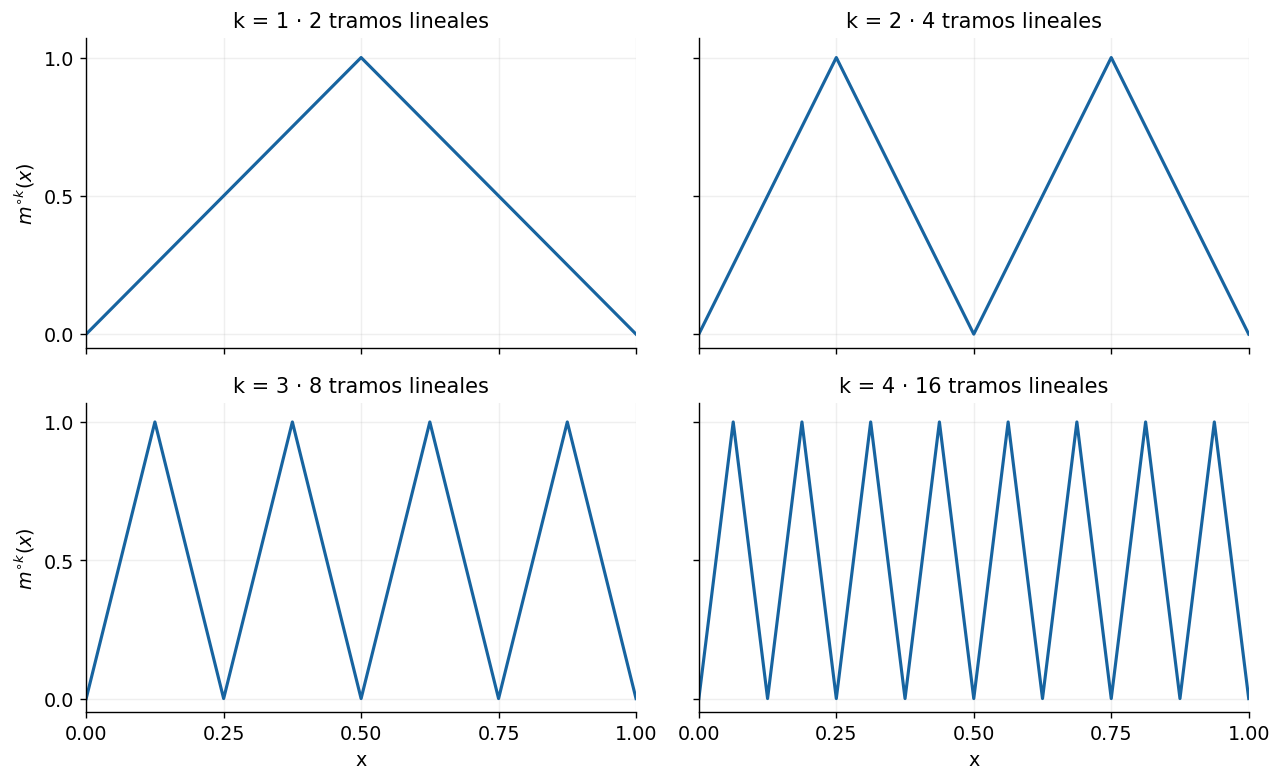


Todas las comprobaciones finalizaron sin errores.


In [7]:
def tienda(x):
    x = np.asarray(x, dtype=float)
    return 2 * np.maximum(x, 0) - 4 * np.maximum(x - 0.5, 0)


def composicion_tienda(x, k):
    resultado = np.asarray(x, dtype=float).copy()
    for _ in range(k):
        resultado = tienda(resultado)
    return resultado


def red_ancho_dos(x, k):
    if k < 1:
        raise ValueError("k debe ser un entero positivo.")
    x = np.asarray(x, dtype=float)
    h = np.vstack((np.maximum(x, 0), np.maximum(x - 0.5, 0)))
    pesos = np.array([[2.0, -4.0], [2.0, -4.0]])
    sesgos = np.array([[0.0], [-0.5]])
    for _ in range(1, k):
        h = np.maximum(pesos @ h + sesgos, 0)
    return np.array([2.0, -4.0]) @ h


x_malla = np.linspace(0, 1, 4097)
print("k   Capas   Ancho   Tramos medidos   2^k   Error máximo")
for k in range(1, 7):
    por_composicion = composicion_tienda(x_malla, k)
    por_red = red_ancho_dos(x_malla, k)
    np.testing.assert_allclose(por_composicion, por_red, atol=1e-12, rtol=0)
    pendientes = np.diff(por_composicion) / np.diff(x_malla)
    tramos = 1 + np.count_nonzero(
        ~np.isclose(pendientes[1:], pendientes[:-1], atol=1e-10, rtol=0)
    )
    assert tramos == 2**k
    error = np.max(np.abs(por_composicion - por_red))
    print(f"{k:1d} {k:7d} {2:7d} {tramos:16d} {2**k:5d}   {error:.3e}")

fig, ejes = plt.subplots(2, 2, figsize=(10.4, 6.4), sharex=True, sharey=True)
for k, eje in enumerate(ejes.flat, start=1):
    eje.plot(
        x_malla, composicion_tienda(x_malla, k),
        color=COLORES[0], linewidth=1.8
    )
    eje.set_title(f"k = {k} · {2**k} tramos lineales")
    eje.set_xlim(0, 1)
    eje.set_ylim(-0.05, 1.07)
    eje.set_xticks([0, 0.25, 0.5, 0.75, 1])
    eje.set_yticks([0, 0.5, 1])
    eje.grid(alpha=0.2)
for eje in ejes[1, :]:
    eje.set_xlabel("x")
for eje in ejes[:, 0]:
    eje.set_ylabel(r"$m^{\circ k}(x)$")
fig.tight_layout()
guardar_figura(fig, "profundidad")
plt.show()
plt.close(fig)
print("\nTodas las comprobaciones finalizaron sin errores.")
